### 1. Project Title

# Car Price Prediction Using Machine Learning

## 1. Project Introduction

The Car Price Prediction project aims to predict the selling price
of used cars based on different vehicle characteristics.

The project uses Machine Learning regression algorithms to estimate
car prices based on brand, car age, kilometers driven, mileage,
fuel type, and transmission.

### Project Objectives
- Perform data cleaning and preprocessing.
- Analyze used car dataset using EDA.
- Extract brand and calculate car age.
- Use mileage as an additional feature when available.
- Perform categorical encoding.
- Train two regression models.
- Evaluate models using MAE, RMSE, and R².
- Select the best-performing model.
- Visualize feature importance.
- Save the trained model for future predictions.

### Technologies Used
Python, Pandas, NumPy, Matplotlib, Seaborn,
Scikit-learn, Joblib and Jupyter Notebook.

### 2. Libraries Import

In [7]:
import os
import re
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score)
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
print("All libraries imported successfully!")

All libraries imported successfully!


### 3. Dataset Loading

Load the used car dataset from the data folder.

In [8]:
DATA_PATH = os.path.join("data", "car_data.csv")
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")
df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully!")
display(df.head())

Dataset loaded successfully!


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


### 4. Dataset Inspection

Inspect dataset shape, columns, data types, statistical summary, and missing values.

In [9]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all").T)

print("\nMissing Values:")
display(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape: (4340, 8)

Column Names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 515.2 KB

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,4340,1491,Maruti Swift Dzire VDI,69,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,4340.0,NaN,NaN,NaN,2013.090783,4.215344,1992.0,2011.0,2014.0,2016.0,2020.0
selling_price,4340.0,NaN,NaN,NaN,504127.311751,578548.736139,20000.0,208749.75,350000.0,600000.0,8900000.0
km_driven,4340.0,NaN,NaN,NaN,66215.777419,46644.102194,1.0,35000.0,60000.0,90000.0,806599.0
fuel,4340,5,Diesel,2153,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_type,4340,3,Individual,3244,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,4340,2,Manual,3892,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,4340,5,First Owner,2832,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing Values:


name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64


Duplicate Rows:
763


### 5. Data Cleaning

Remove duplicate records, handle missing values, correct data types, and standardize categorical values.

In [10]:
df = df.copy()
df.columns = df.columns.str.strip()
df.drop_duplicates(inplace=True)

for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].astype("string").str.strip()

for col in ["fuel", "transmission", "seller_type", "owner"]:
    if col in df.columns:
        df[col] = df[col].str.lower()

for col in ["year", "selling_price", "km_driven"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

required_columns = ["name", "year", "selling_price", "km_driven"]

for col in required_columns:
    if col not in df.columns:
        raise ValueError(f"Required column missing: {col}")

df.dropna(subset=required_columns, inplace=True)
df = df[(df["selling_price"] > 0) & (df["km_driven"] >= 0)].copy()
print("Data cleaning completed!")
print("Cleaned Dataset Shape:", df.shape)
print("\nMissing Values After Cleaning:")
display(df.isnull().sum())

Data cleaning completed!
Cleaned Dataset Shape: (3577, 8)

Missing Values After Cleaning:


name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

### 6. Feature Engineering

Create new features such as car age and brand from the car name.

In [11]:
df["brand"] = df["name"].str.split().str[0]
CURRENT_YEAR = datetime.now().year
df["car_age"] = CURRENT_YEAR - df["year"]
df = df[df["car_age"] >= 0].copy()
print("Brand and Car Age features created!")
display(df[["name", "brand", "year", "car_age"]].head())

Brand and Car Age features created!


,name,brand,year,car_age
0,Maruti 800 AC,Maruti,2007,19
1,Maruti Wagon R LXI Minor,Maruti,2007,19
2,Hyundai Verna 1.6 SX,Hyundai,2012,14
3,Datsun RediGO T Option,Datsun,2017,9
4,Honda Amaze VX i-DTEC,Honda,2014,12


### 7. Mileage Feature Engineering

In [12]:
mileage_columns = [col for col in df.columns if "mileage" in col.lower()]
if mileage_columns:
    mileage_col = mileage_columns[0]
    df["mileage_value"] = pd.to_numeric(df[mileage_col].astype(str).str.extract(r"(\d+\.?\d*)")[0], errors="coerce")
    df["mileage_unit"] = (df[mileage_col].astype(str).str.lower().str.extract(r"(kmpl|km/kg)", expand=False))
    df["mileage_unit"] = df["mileage_unit"].fillna("unknown")
    print("Mileage feature found:", mileage_col)
else:
    print("Mileage column not available.")
    print("Model will use other available features.")
display(df[["name", "km_driven", "brand", "car_age"] + (["mileage_value", "mileage_unit"] if "mileage_value" in df.columns else [])].head())

Mileage column not available.
Model will use other available features.


,name,km_driven,brand,car_age
0,Maruti 800 AC,70000,Maruti,19
1,Maruti Wagon R LXI Minor,50000,Maruti,19
2,Hyundai Verna 1.6 SX,100000,Hyundai,14
3,Datsun RediGO T Option,46000,Datsun,9
4,Honda Amaze VX i-DTEC,141000,Honda,12


### 7. EDA Graphs

Analyze selling price distribution, car age, fuel type, and their relationship with selling price.

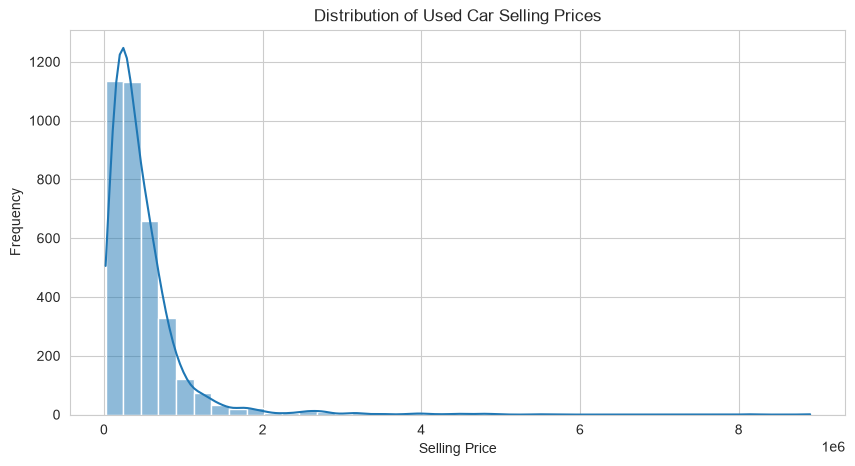

In [13]:
#Exploratory Data Analysis
plt.figure(figsize=(10, 5))
sns.histplot(df["selling_price"], bins=40, kde=True)
plt.title("Distribution of Used Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Frequency")
plt.show()

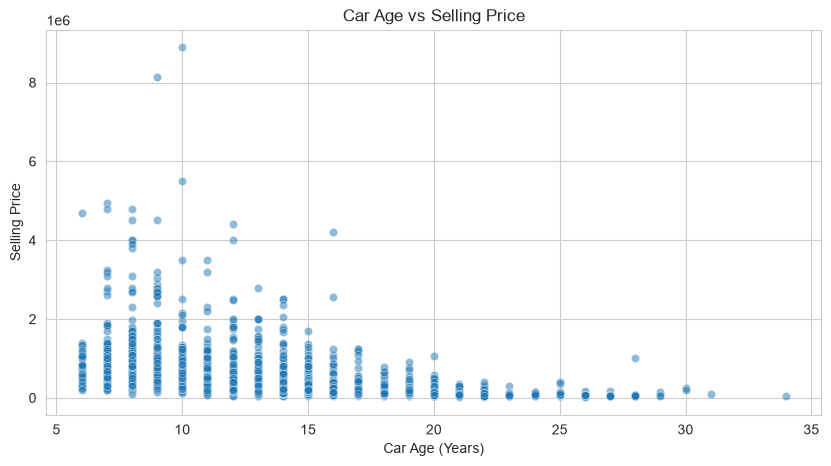

In [14]:
# Car Age vs Selling Price
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x="car_age", y="selling_price", alpha=0.5)
plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price")
plt.show()

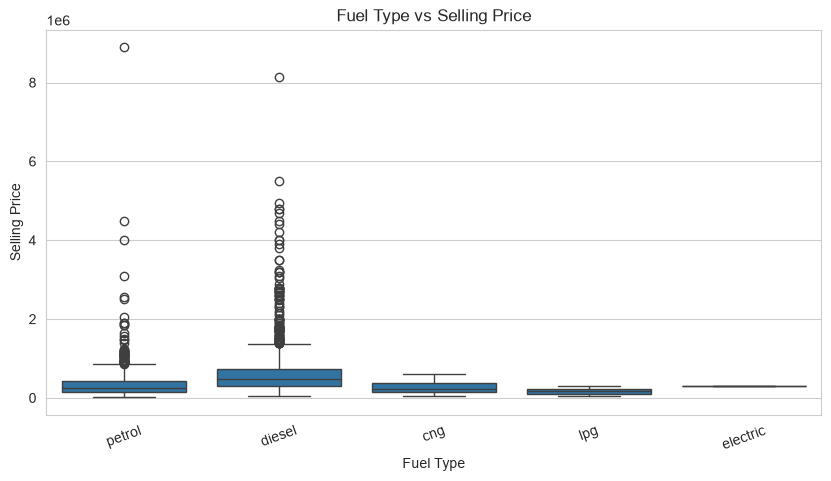

In [15]:
# Fuel Type vs Selling Price
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="fuel", y="selling_price")
plt.title("Fuel Type vs Selling Price")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")
plt.xticks(rotation=20)
plt.show()

In [16]:
# Mileage vs Selling Price
if "mileage_value" in df.columns:
    plt.figure(figsize=(10, 5))
    sns.scatterplot(data=df, x="mileage_value", y="selling_price", hue="fuel", alpha=0.6)
    plt.title("Mileage vs Selling Price")
    plt.xlabel("Mileage (km/l or km/kg)")
    plt.ylabel("Selling Price")
    plt.show()
else:
    print("Mileage visualization skipped because column is unavailable.")

Mileage visualization skipped because column is unavailable.


### 8. Correlation Heatmap

Visualize the correlation between numerical features to understand their relationships.

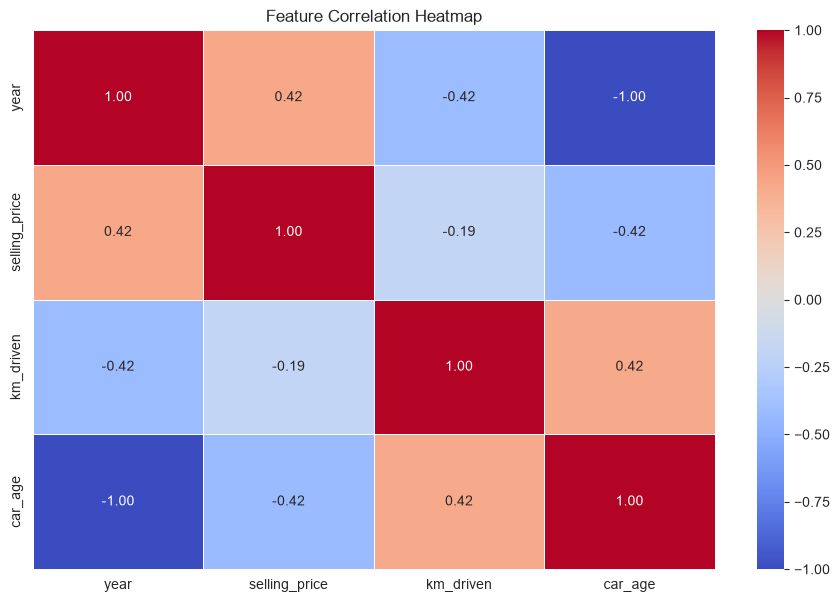

In [17]:
numeric_df = df.select_dtypes(include=np.number)
correlation_matrix = numeric_df.corr()
plt.figure(figsize=(11, 7))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.show()

### 9. Feature Selection

Select relevant input features and the target variable.

In [18]:
feature_columns = ["brand", "car_age", "km_driven", "fuel", "transmission"]

if "mileage_value" in df.columns:
    feature_columns.append("mileage_value")

if "mileage_unit" in df.columns:
    feature_columns.append("mileage_unit")

X = df[feature_columns].copy()
y = df["selling_price"].copy()

print("Selected Features:")
print(feature_columns)

print("\nInput Shape:", X.shape)
print("Target Shape:", y.shape)
display(X.head())

Selected Features:
['brand', 'car_age', 'km_driven', 'fuel', 'transmission']

Input Shape: (3577, 5)
Target Shape: (3577,)


,brand,car_age,km_driven,fuel,transmission
0,Maruti,19,70000,petrol,manual
1,Maruti,19,50000,petrol,manual
2,Hyundai,14,100000,diesel,manual
3,Datsun,9,46000,petrol,manual
4,Honda,12,141000,diesel,manual


### 10. Categorical Encoding

Use OneHotEncoder to convert categorical features into numerical format. 
Missing categorical and numerical values are handled using imputers.

In [19]:
categorical_features = ["brand", "fuel", "transmission"]
numerical_features = ["car_age", "km_driven"]

if "mileage_value" in X.columns:
    numerical_features.append("mileage_value")
if "mileage_unit" in X.columns:
    categorical_features.append("mileage_unit")
numerical_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="median"))])

categorical_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer(transformers=[("num", numerical_transformer, numerical_features), ("cat", categorical_transformer, categorical_features)])
print("Categorical encoding configured successfully!")

Categorical encoding configured successfully!


### 11. Train-Test Split

Split the dataset into 80% training data and 20% testing data.

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)
print("Train-Test Split Completed!")

Training Data: (2861, 5)
Testing Data: (716, 5)
Train-Test Split Completed!


### 12. Two Regression Models

Train two regression algorithms:
1. Linear Regression
2. Random Forest Regressor

In [21]:
models = {"Linear Regression": LinearRegression(), "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)}
trained_models = {}
for model_name, model in models.items():
    pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])
    pipeline.fit(X_train, y_train)
    trained_models[model_name] = pipeline
    print(model_name, "trained successfully!")

Linear Regression trained successfully!
Random Forest trained successfully!


### 13. Model Evaluation

Evaluate model performance using:
- MAE: Mean Absolute Error
- RMSE: Root Mean Squared Error
- R²: Coefficient of Determination

In [22]:
results = []
for model_name, model in trained_models.items():
    predictions = model.predict(X_test)
    mae = mean_absolute_error(y_test, predictions)                                   # Calculate MAE
    rmse = np.sqrt(mean_squared_error(y_test, predictions))                          # Calculate RMSE
    r2 = r2_score(y_test, predictions)                                               # Calculate R2 Score
    results.append({"Model": model_name, "MAE": mae, "RMSE": rmse, "R2 Score": r2})
    print("\nModel:", model_name)
    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R2 Score:", round(r2, 4))


Model: Linear Regression
MAE: 208837.23
RMSE: 434710.72
R2 Score: 0.4134

Model: Random Forest
MAE: 160022.67
RMSE: 368479.39
R2 Score: 0.5785


### 14 — Model Comparison

Compare both regression models using MAE, RMSE, and R².
Lower MAE and RMSE indicate lower prediction errors.
Higher R² indicates better explanatory performance.

,Model,MAE,RMSE,R2 Score
1,Random Forest,160022.673066,368479.390552,0.578507
0,Linear Regression,208837.231178,434710.715198,0.413369


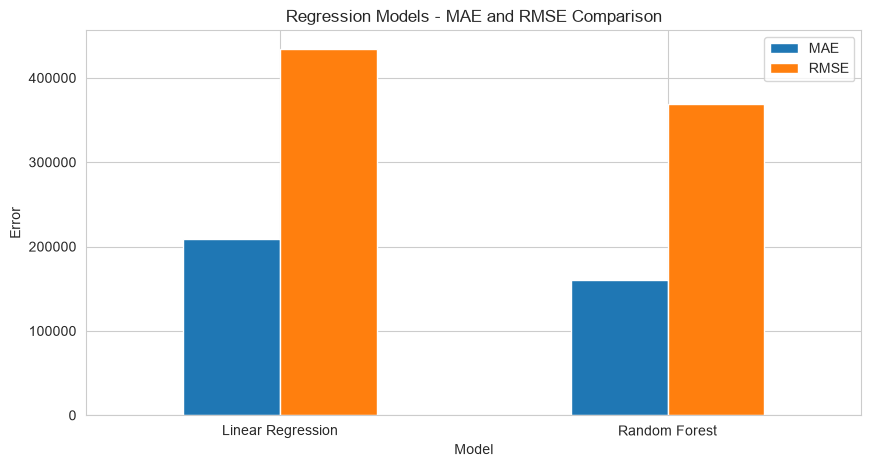

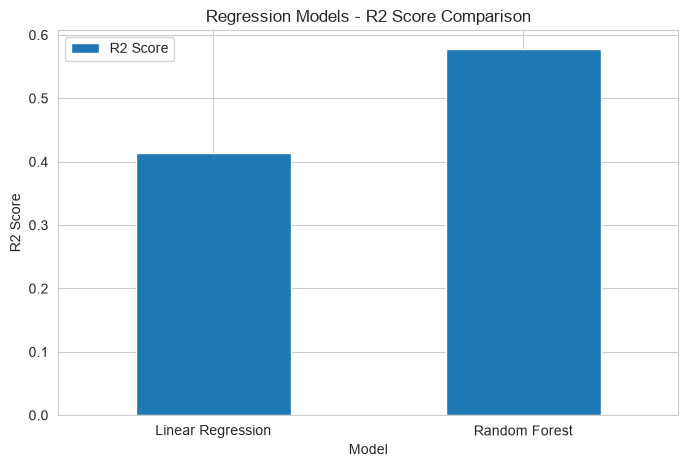

In [23]:
results_df = pd.DataFrame(results)
display(results_df.sort_values(by="MAE"))
results_df.set_index("Model")[["MAE", "RMSE"]].plot(kind="bar", figsize=(10, 5))              # Compare MAE and RMSE
plt.title("Regression Models - MAE and RMSE Comparison")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.show()

results_df.set_index("Model")[["R2 Score"]].plot(kind="bar", figsize=(8, 5))                  # Compare R2 Score
plt.title("Regression Models - R2 Score Comparison")
plt.ylabel("R2 Score")
plt.xticks(rotation=0)
plt.show()

### 15. Best Model Selection

Select the model with the lowest MAE score.

In [24]:
best_model_name = results_df.loc[results_df["MAE"].idxmin(), "Model"]
best_model = trained_models[best_model_name]
print("Best Performing Model:", best_model_name)
display(results_df[results_df["Model"] == best_model_name])

Best Performing Model: Random Forest


,Model,MAE,RMSE,R2 Score
1,Random Forest,160022.673066,368479.390552,0.578507


### 16. Feature Importance Chart

Analyze which features contribute most to predictions.
For Random Forest, use feature importance.
For Linear Regression, use absolute coefficient magnitude.

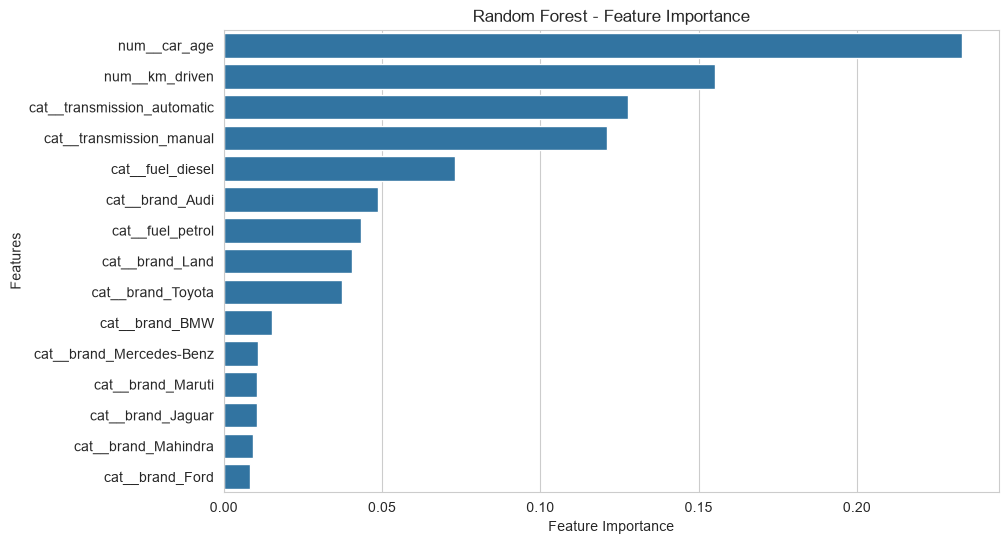

,Feature,Importance
0,num__car_age,0.233149
1,num__km_driven,0.155288
33,cat__transmission_automatic,0.127686
34,cat__transmission_manual,0.121083
30,cat__fuel_diesel,0.073156
3,cat__brand_Audi,0.048824
32,cat__fuel_petrol,0.043270
15,cat__brand_Land,0.040462
26,cat__brand_Toyota,0.037459
4,cat__brand_BMW,0.015186


In [25]:
fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_estimator = best_model.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()
if hasattr(fitted_estimator, "feature_importances_"):
    importance_values = fitted_estimator.feature_importances_
    importance_label = "Feature Importance"
elif hasattr(fitted_estimator, "coef_"):
    importance_values = np.abs(np.ravel(fitted_estimator.coef_))
    importance_label = "Absolute Coefficient Magnitude"
else:
    raise TypeError("Feature importance is not supported.")

importance_df = pd.DataFrame({"Feature": feature_names, "Importance": importance_values})
importance_df = importance_df.sort_values(by="Importance", ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x="Importance", y="Feature")
plt.title(f"{best_model_name} - {importance_label}")
plt.xlabel(importance_label)
plt.ylabel("Features")
plt.show()
display(importance_df)

### 17. Model Saving

Save the selected trained model using Joblib for future predictions.

In [26]:
os.makedirs("models", exist_ok=True)
MODEL_PATH = "models/best_car_price_model.pkl"
joblib.dump(best_model, MODEL_PATH)
print("Model saved successfully!")
print("Model Location:", MODEL_PATH)

Model saved successfully!
Model Location: models/best_car_price_model.pkl


### 18. Sample Car Price Prediction

Use the saved model to predict the selling price of a sample used car.

In [27]:
loaded_model = joblib.load(MODEL_PATH)
sample_data = {"brand": "Maruti", "car_age": 5, "km_driven": 45000, "fuel": "petrol", "transmission": "manual"}

if "mileage_value" in X.columns:
    sample_data["mileage_value"] = 20.0

if "mileage_unit" in X.columns:
    available_units = (X["mileage_unit"].dropna().unique().tolist())
    sample_data["mileage_unit"] = ("kmpl" if "kmpl" in available_units else available_units[0])

sample_car = pd.DataFrame([sample_data])
predicted_price = loaded_model.predict(sample_car)[0]

print("Sample Car Details:")
display(sample_car)

print("Predicted Car Price: {:,.2f}".format(predicted_price))

Sample Car Details:


,brand,car_age,km_driven,fuel,transmission
0,Maruti,5,45000,petrol,manual


Predicted Car Price: 479,611.93


### 19. Project Conclusion

The Car Price Prediction project successfully demonstrates the application of Machine Learning 
regression algorithms to estimate used car selling prices.

The dataset was cleaned and analyzed using Exploratory Data Analysis.
Feature engineering was performed to extract car brands and calculate car age. 
Mileage was also included as an additional feature whenever it was available in the dataset.

Linear Regression and Random Forest Regression models were trained and evaluated using
MAE, RMSE, and R² metrics.

The best-performing model was selected based on the lowest MAE score.
Feature importance analysis was performed to understand the influence of different vehicle
characteristics on predicted prices.

Finally, the trained model pipeline was saved using Joblib for future predictions.

This project demonstrates how Machine Learning can support data-driven used car price estimation.

### 20. Final Verification

In [28]:
print("========== PROJECT VERIFICATION ==========")
print("Dataset Shape:", df.shape)
print("Mileage Used:", "mileage_value" in X.columns)
print("Selected Features:", feature_columns)
print("Models Trained:", list(trained_models.keys()))
print("Best Model:", best_model_name)
print("Model Saved:", os.path.exists(MODEL_PATH))
print("Feature Importance Generated:", not importance_df.empty)
print("Evaluation Completed:", not results_df.empty)
print("\nFinal Model Results:")
display(results_df)
print("\nAll project sections executed successfully!")
print("==========================================")

========== PROJECT VERIFICATION ==========
Dataset Shape: (3577, 10)
Mileage Used: False
Selected Features: ['brand', 'car_age', 'km_driven', 'fuel', 'transmission']
Models Trained: ['Linear Regression', 'Random Forest']
Best Model: Random Forest
Model Saved: True
Feature Importance Generated: True
Evaluation Completed: True

Final Model Results:


,Model,MAE,RMSE,R2 Score
0,Linear Regression,208837.231178,434710.715198,0.413369
1,Random Forest,160022.673066,368479.390552,0.578507



All project sections executed successfully!
